[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/arvidl/BMED365-2027/blob/main/Lab4-Comp-Imag/Kiwi-challenge/docs/neurosymbolic-report/notebooks/05_axiom_stress_tests_and_clinical_translation.ipynb)

# Companion Notebook 05 — Axiom Misspecification & Pathological Mass-Effect Stress Test

*Companion to the BMED365 Technical Report (`../neurosymbolic-kiwi-report.pdf`)*  
*Reproduces: **Section 3.5**, **Section 4.2**, **Figure 9**, and **Table 7** (`../results/nb05_stress_test.json`)*

### Purpose
In clinical medicine, **pathology frequently breaks textbook anatomy**: a large glioblastoma induces **midline shift and mass effect**, displacing brain structures by `5–15 mm` relative to a rigid template! Here we stress-test our trained models under **synthetic organ center shifts** ($\Delta r \in [0, 8]\text{ mm}$) and **radial scale errors** ($\alpha \in [0.80, 1.25]$), comparing:
1. **Hard Post-Hoc Masking (`Baseline U-Net × Rigid Ring Mask`)** — brittle binary symbolic veto.
2. **Soft Differentiable `AdditiveBayesOrganNet3D` (`Rigid-Template Organ-GPS`)** — trained with soft LTN axioms, tested with mismatched coordinates.
3. **Patient-Adapted `AdditiveBayesOrganNet3D` (`Deformable / Re-Centered Organ-GPS`)** — the clinical safeguard.
4. **Unmasked Pure Neural `Baseline U-Net`** — locally shift-invariant, yet globally unsafe (`197k` OOD voxels).

In [1]:
import json
import sys
import urllib.request
from pathlib import Path

# Auto-fetch shared library `kiwi_ns_lib.py` if opened standalone in Google Colab
if not Path("kiwi_ns_lib.py").exists():
    for cand in [Path("docs/neurosymbolic-report/notebooks/kiwi_ns_lib.py"),
                 Path("Lab4-Comp-Imag/Kiwi-challenge/docs/neurosymbolic-report/notebooks/kiwi_ns_lib.py")]:
        if cand.exists():
            sys.path.insert(0, str(cand.parent.resolve()))
            break
    else:
        url = "https://raw.githubusercontent.com/arvidl/BMED365-2027/main/Lab4-Comp-Imag/Kiwi-challenge/docs/neurosymbolic-report/notebooks/kiwi_ns_lib.py"
        print("Downloading kiwi_ns_lib.py from GitHub main for Colab session...")
        urllib.request.urlretrieve(url, "kiwi_ns_lib.py")

if str(Path.cwd()) not in sys.path:
    sys.path.insert(0, str(Path.cwd()))

import importlib.util
for pkg in ("nibabel", "torch"):
    if importlib.util.find_spec(pkg) is None:
        import subprocess
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

get_ipython().run_line_magic("matplotlib", "inline")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from scipy import ndimage as ndi
from scipy.spatial.distance import cdist
from skimage import measure

plt.rcParams.update({"figure.dpi": 130, "savefig.dpi": 200, "font.size": 9.5})

import kiwi_ns_lib as kns

DEVICE = kns.get_best_device()
FIG_DIR, RES_DIR = kns.resolve_report_dirs()
print(f"Device: {DEVICE} | Figures -> {FIG_DIR} | Results -> {RES_DIR}")

Device: mps | Figures -> /Users/arvid/GitHub/BMED365-2027/Lab4-Comp-Imag/Kiwi-challenge/docs/neurosymbolic-report/figures | Results -> /Users/arvid/GitHub/BMED365-2027/Lab4-Comp-Imag/Kiwi-challenge/docs/neurosymbolic-report/results


## 1. Run Mass-Effect Center-Shift & Radial-Scale Misspecification Stress Tests

,shift_mm,hard_mask_PQ,hard_mask_Rec,hard_mask_Pred,soft_ltn_PQ,soft_ltn_Rec,soft_ltn_Pred,adapted_ltn_PQ,unmasked_base_PQ
0,0.0,0.3267,0.5769,57,0.4734,0.5385,32,0.4734,0.2968
1,2.0,0.3282,0.5769,51,0.4617,0.5192,31,0.4734,0.2968
2,4.0,0.2293,0.3462,31,0.4621,0.5192,30,0.4734,0.2968
3,6.0,0.0896,0.1154,13,0.4524,0.5192,30,0.4734,0.2968
4,8.0,0.0000,0.0000,2,0.4328,0.5192,30,0.4734,0.2968


,radial_scale,hard_mask_PQ,hard_mask_Rec,soft_ltn_PQ,soft_ltn_Rec
0,0.80,0.2394,0.3654,0.4598,0.5192
1,0.90,0.3397,0.5769,0.4606,0.5192
2,1.00,0.3267,0.5769,0.4734,0.5385
3,1.10,0.3070,0.5769,0.4710,0.5385
4,1.25,0.2993,0.5769,0.4625,0.5385


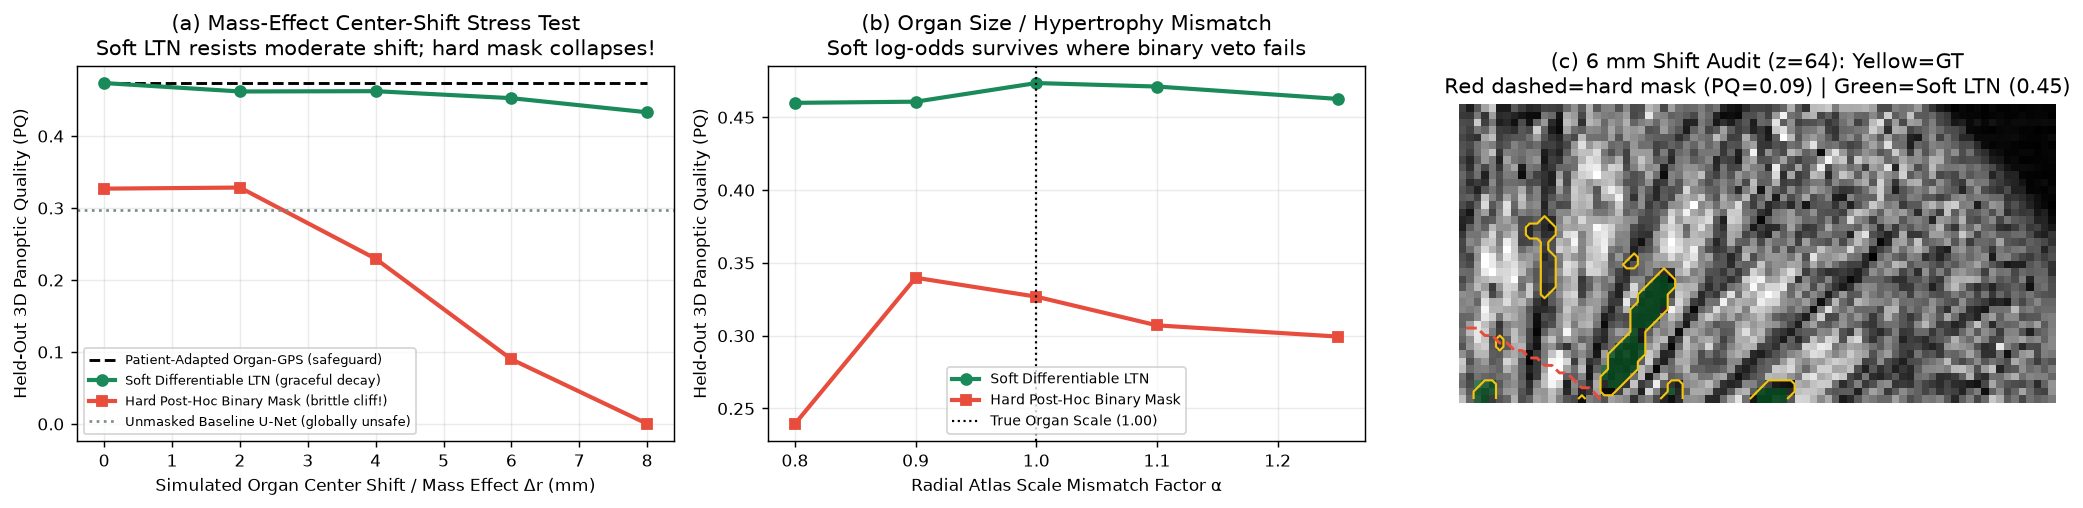

In [2]:
ds = kns.load_kiwi_dataset()
ssl_bb, _ = kns.pretrain_ssl_backbone(ds, DEVICE, seed=2027, epochs=100)
ubank = kns.sample_unlabeled_blocks(ds, DEVICE, n_blocks=40, seed=2027)

m_base, _, _ = kns.train_neurosymbolic_variant(ds, DEVICE, mode="baseline", epochs=100, seed=2027)
m_ns, _, _ = kns.train_neurosymbolic_variant(
    ds, DEVICE, mode="additive_gps", ssl_backbone=ssl_bb, unlabeled_bank=ubank,
    p_quant=3.0, w_comp=2.0, w_t2=1.2, gps_lr=1.5e-2, epochs=100, seed=2027,
)
thr_cal = kns.calibrate_threshold_on_train(m_ns, "additive_gps", ds, DEVICE, use_split=True)

# Precompute baseline U-Net test probabilities once (purely local texture -> invariant to coordinate shifts)
res_base_unmasked = kns.run_test_and_whole_fruit(m_base, "baseline", ds, DEVICE, thresh=0.50, use_split=False, do_whole_fruit=False)
res_ns_adapted = kns.run_test_and_whole_fruit(m_ns, "additive_gps", ds, DEVICE, thresh=thr_cal, use_split=True, do_whole_fruit=False)

# Stress Test 1: Synthetic organ center displacement (0 .. 8 mm, simulating clinical mass-effect / midline shift!)
shifts_mm = [0.0, 2.0, 4.0, 6.0, 8.0]
shift_rows = []
demo_4mm = {}

for s_mm in shifts_mm:
    # Shift organ center diagonally away from the test sector (+x, +y -> shifts true seeds toward inner/outer walls!)
    dv = (s_mm / ds.spacing[0]) / np.sqrt(2.0)
    _, r_sh, z_sh, ring_sh = kns.build_whole_organ_geometry(ds.vol, ds.spacing, center_shift_vox=(-dv, -dv, 0.0), radial_scale=1.0)
    pole_sh = (np.abs(z_sh - 0.5) * 2.0).astype(np.float32)

    # 1. Hard Post-Hoc Binary Ring Mask on Baseline U-Net
    ring_te = ring_sh[ds.rx0:ds.rx1, ds.ry0 + ds.split_y : ds.ry1, ds.rz0:ds.rz1] >= 0.50
    lbl_hard = kns.decode_deep_watershed_3d((res_base_unmasked["prob_te"] >= 0.50) & ring_te, res_base_unmasked["dist_te"], ds.spacing)
    ev_hard = kns.evaluate_semantic_and_instance_3d(lbl_hard, ds.test_gt)

    # 2. Soft Differentiable LTN with Rigid (Mismatched) Coordinates
    res_soft = kns.run_test_and_whole_fruit(
        m_ns, "additive_gps", ds, DEVICE, thresh=thr_cal, use_split=True,
        r_override=r_sh, pole_override=pole_sh, do_whole_fruit=False,
    )
    ev_soft = res_soft["ev_te"]

    if abs(s_mm - 6.0) < 1e-6:
        demo_4mm = {"ring_te": ring_te, "lbl_hard": lbl_hard, "lbl_soft": res_soft["pred_te"], "ev_hard": ev_hard, "ev_soft": ev_soft}

    shift_rows.append({
        "shift_mm": s_mm,
        "hard_mask_PQ": ev_hard["PQ"], "hard_mask_Rec": ev_hard["Recall"], "hard_mask_Pred": ev_hard["Pred"],
        "soft_ltn_PQ": ev_soft["PQ"],  "soft_ltn_Rec": ev_soft["Recall"],  "soft_ltn_Pred": ev_soft["Pred"],
        "adapted_ltn_PQ": res_ns_adapted["ev_te"]["PQ"],
        "unmasked_base_PQ": res_base_unmasked["ev_te"]["PQ"],
    })

df_shift = pd.DataFrame(shift_rows)
display(df_shift)

# Stress Test 2: Radial Organ Scale Mismatch (alpha in [0.80 .. 1.25], simulating organ hypertrophy / atrophy)
scales = [0.80, 0.90, 1.00, 1.10, 1.25]
scale_rows = []
for sc in scales:
    _, r_sc, z_sc, ring_sc = kns.build_whole_organ_geometry(ds.vol, ds.spacing, radial_scale=sc)
    pole_sc = (np.abs(z_sc - 0.5) * 2.0).astype(np.float32)
    ring_te = ring_sc[ds.rx0:ds.rx1, ds.ry0 + ds.split_y : ds.ry1, ds.rz0:ds.rz1] >= 0.50
    ev_h = kns.evaluate_semantic_and_instance_3d(
        kns.decode_deep_watershed_3d((res_base_unmasked["prob_te"] >= 0.50) & ring_te, res_base_unmasked["dist_te"], ds.spacing),
        ds.test_gt,
    )
    ev_s = kns.run_test_and_whole_fruit(
        m_ns, "additive_gps", ds, DEVICE, thresh=thr_cal, use_split=True,
        r_override=r_sc, pole_override=pole_sc, do_whole_fruit=False,
    )["ev_te"]
    scale_rows.append({
        "radial_scale": sc,
        "hard_mask_PQ": ev_h["PQ"], "hard_mask_Rec": ev_h["Recall"],
        "soft_ltn_PQ": ev_s["PQ"],  "soft_ltn_Rec": ev_s["Recall"],
    })

df_scale = pd.DataFrame(scale_rows)
display(df_scale)

(RES_DIR / "nb05_stress_test.json").write_text(json.dumps({"center_shift": shift_rows, "radial_scale": scale_rows}, indent=2), encoding="utf-8")

# Figure 9: 3-Panel Axiom Misspecification & Mass-Effect Stress Test
fig, axes = plt.subplots(1, 3, figsize=(16.0, 4.0))

axes[0].plot(df_shift["shift_mm"], df_shift["adapted_ltn_PQ"], "k--", lw=1.6, label="Patient-Adapted Organ-GPS (safeguard)")
axes[0].plot(df_shift["shift_mm"], df_shift["soft_ltn_PQ"], "o-", color="#1b8a5a", lw=2.3, label="Soft Differentiable LTN (graceful decay)")
axes[0].plot(df_shift["shift_mm"], df_shift["hard_mask_PQ"], "s-", color="#e74c3c", lw=2.3, label="Hard Post-Hoc Binary Mask (brittle cliff!)")
axes[0].axhline(res_base_unmasked["ev_te"]["PQ"], color="#7f8c8d", ls=":", lw=1.5, label="Unmasked Baseline U-Net (globally unsafe)")
axes[0].set_xlabel("Simulated Organ Center Shift / Mass Effect Δr (mm)")
axes[0].set_ylabel("Held-Out 3D Panoptic Quality (PQ)")
axes[0].set_title("(a) Mass-Effect Center-Shift Stress Test\nSoft LTN resists moderate shift; hard mask collapses!")
axes[0].legend(fontsize=7.2, loc="lower left")
axes[0].grid(alpha=0.25)

axes[1].plot(df_scale["radial_scale"], df_scale["soft_ltn_PQ"], "o-", color="#1b8a5a", lw=2.3, label="Soft Differentiable LTN")
axes[1].plot(df_scale["radial_scale"], df_scale["hard_mask_PQ"], "s-", color="#e74c3c", lw=2.3, label="Hard Post-Hoc Binary Mask")
axes[1].axvline(1.00, color="k", ls=":", lw=1.2, label="True Organ Scale (1.00)")
axes[1].set_xlabel("Radial Atlas Scale Mismatch Factor α")
axes[1].set_ylabel("Held-Out 3D Panoptic Quality (PQ)")
axes[1].set_title("(b) Organ Size / Hypertrophy Mismatch\nSoft log-odds survives where binary veto fails")
axes[1].legend(fontsize=7.5, loc="lower center")
axes[1].grid(alpha=0.25)

# Panel (c): Visual comparison at 6 mm mass-effect shift on mid-test slice z=64
zm = 8
te_vn = ds.vol_norm[ds.rx0:ds.rx1, ds.ry0 + ds.split_y : ds.ry1, ds.rz0:ds.rz1]
axes[2].imshow(te_vn[:, :, zm].T, cmap="gray", origin="lower")
axes[2].contour(ds.test_gt[:, :, zm].T > 0, levels=[0.5], colors=["#f1c40f"], linewidths=1.2)
axes[2].contour(demo_4mm["ring_te"][:, :, zm].T, levels=[0.5], colors=["#e74c3c"], linewidths=1.6, linestyles="--")
soft_fg = demo_4mm["lbl_soft"][:, :, zm].T > 0
axes[2].imshow(np.ma.masked_where(~soft_fg, soft_fg), cmap="Greens", alpha=0.55, origin="lower", vmin=0, vmax=1.2)
axes[2].set_title(f"(c) 6 mm Shift Audit (z=64): Yellow=GT\nRed dashed=hard mask (PQ={demo_4mm['ev_hard']['PQ']:.2f}) | Green=Soft LTN ({demo_4mm['ev_soft']['PQ']:.2f})")
axes[2].axis("off")

plt.tight_layout()
fig.savefig(FIG_DIR / "fig09_mass_effect_stress_test.png", bbox_inches="tight")
plt.show()